# C02k — Punctuation mutability stacks on controlled rewrites
Input is exclusively completed C02j controlled-regeneration checkpoints. Poetry is excluded; no original or ordinary AI text substitutes for missing controlled output. The cohort is therefore the non-poetry subset of the previous 30, unless additional controlled cases are supplied in its manifest. This notebook does not regenerate texts.

Nontrivial punctuation first, comma/period second. Natural question/exclamation marks are preserved. Finite, conservative templates provide both increment and decrement candidates; unsupported vertices remain unchanged. Reparse and rescore all candidates after every accepted edit. Local scorer: frozen GPT-2, no sampling. Mutability = min(1, exp(candidate mean log likelihood minus original mean log likelihood)), scored over replacement plus fixed right context, conditioned on fixed left context. Higher means more mutable. A standard sigmoid lowers the acceptance bar with normalized deviation. Parameters are exploratory and not calibrated grammaticality probabilities.

This first stack experiment targets **whole-text Q20–Q60 human ranges, recovering toward Q40**, separately per punctuation mark, using the exact FZ count/character denominator. It does not enforce prefix punctuation bands. Humans are 30 nearest-length non-poetry RAID training texts (pooled across genres for this feasibility run); reference identities and all thresholds are frozen per case. Unicode dash ratios are separately tracked because FZ-118 counts only ASCII hyphens. Word-internal hyphens and numerical punctuation are protected.

Acceptance requires the mark count to move in the intended direction and its distance to Q40 to decrease. A strictly decreasing stage objective prevents cycling. No edit budget. Stage 2 cannot change nontrivial counts. Unique-word changes are measured, not silently assumed absent; this paired experiment does not establish causal isolation. Manual review remains necessary for semantic validity. All before/after features and frozen-detector scores are saved.

In [1]:
IMPLEMENTATION_HASH='e3d58709b0c7fb1d252e80f7433dff35171439857ece1668e03c9f24ba3c4453'
from pathlib import Path
import json, math, time, hashlib, os, re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import spacy, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
ROOT=Path('..')
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR=ROOT/'results/causal/C02e2_raid_feature_guided'
SOURCE=ROOT/'results/causal/C02j_fz118_residual_30'
OUT=ROOT/'results/causal/C02k_punctuation_stacks'
OUT.mkdir(parents=True,exist_ok=True)
SCORER_ID='openai-community/gpt2'
SCORER_REVISION='main'
LEFT_WORDS=48; RIGHT_WORDS=32
BAR_MIN=.05; BAR_MAX=.95; SLOPE=4.; MIDPOINT=1.
MARKS={'semicolon':';','colon':':','hyphen':'-','en_dash':'–','em_dash':'—','comma':',','period':'.'}
STAGES=[['semicolon','colon','hyphen','en_dash','em_dash'],['comma','period']]
nlp=spacy.load('en_core_web_sm')
def normalize(t):return t.replace('\n',' ').replace('\r',' ')
def words(t):return [x.text.lower() for x in nlp.make_doc(normalize(t)) if x.is_alpha]
def unique(t):
    w=words(t);return len(set(w))/len(w) if w else 0.
def digest(v):return hashlib.sha256(json.dumps(v,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def save(path,v):
    tmp=path.with_suffix('.tmp');tmp.write_text(json.dumps(v,ensure_ascii=False,indent=2));os.replace(tmp,path)
def rates(t):return {m:t.count(ch)/max(1,len(normalize(t))) for m,ch in MARKS.items()}
def bar(q):return BAR_MIN+(BAR_MAX-BAR_MIN)/(1+math.exp(max(-60,min(60,SLOPE*(q-MIDPOINT)))))

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map=corpus.set_index('source_id').text.to_dict()
manifest=pd.read_csv(SOURCE/'selection_30.csv')
excluded=manifest.loc[manifest.domain.astype(str).str.lower().eq('poetry')]
manifest=manifest.loc[~manifest.domain.astype(str).str.lower().eq('poetry')].copy()
humans=features.loc[(features.dataset=='raid')&(features.split=='train')&(features.label==0)
    &~features.domain.astype(str).str.lower().eq('poetry')].copy()
assert len(humans)>=30
source_contract=json.loads((SOURCE/'frozen_contract.json').read_text())
source_hash=digest(source_contract)
cases=[]
for row in manifest.to_dict('records'):
    path=SOURCE/row['case_id']/'controlled/state.json'
    assert path.exists(), f'Missing controlled rewrite: {path}'
    payload=json.loads(path.read_text());s=payload['state']
    assert payload['contract_hash']==source_hash
    assert s['finished'] and s['status']=='completed_eos', f"Incomplete controlled rewrite: {row['case_id']}"
    t=s['committed_text'];assert words(t)==s['words']
    pool=humans.copy();pool['distance']=abs(np.log(pool.n_words.clip(lower=1))-np.log(max(1,len(words(t)))))
    refs=pool.sort_values(['distance','source_id']).head(30)
    rr=pd.DataFrame([rates(str(text_map[i])) for i in refs.source_id])
    bounds={m:dict(zip(['low','center','high'],map(float,rr[m].quantile([.2,.4,.6])))) for m in MARKS}
    cases.append(dict(case_id=row['case_id'],domain=row['domain'],text=t,source_id=row['source_id'],
        bounds=bounds,reference_ids=refs.source_id.tolist()))
print('Completed controlled inputs:',len(cases),'| poetry excluded:',len(excluded))
display(pd.DataFrame([dict(case_id=c['case_id'],domain=c['domain'],words=len(words(c['text'])),unique=unique(c['text'])) for c in cases]))

Completed controlled inputs: 26 | poetry excluded: 4


,case_id,domain,words,unique
0,raid_residual_01,abstracts,69,0.739130
1,raid_residual_02,books,105,0.676190
2,raid_residual_03,news,218,0.577982
3,raid_residual_05,recipes,302,0.460265
4,raid_residual_06,reddit,99,0.686869
5,raid_residual_07,reviews,240,0.608333
6,raid_residual_08,wiki,135,0.629630
7,raid_residual_09,abstracts,145,0.744828
8,raid_residual_10,books,263,0.589354
9,raid_residual_11,news,113,0.690265


In [3]:
tokenizer=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION)
device='cuda' if torch.cuda.is_available() else 'cpu';model.to(device).eval()
# Score at most the model context; reject overflow rather than silently truncating.
@torch.inference_mode()
def continuation_score(left,tail):
    enc=tokenizer(left+tail,return_offsets_mapping=True,return_tensors='pt',add_special_tokens=False)
    offsets=enc.pop('offset_mapping')[0].tolist();ids=enc['input_ids'].to(device)
    if ids.shape[1]<2 or ids.shape[1]>model.config.max_position_embeddings:return None
    logp=model(input_ids=ids).logits[0,:-1].log_softmax(-1)
    chosen=logp.gather(1,ids[0,1:,None]).squeeze(1)
    mask=torch.tensor([end>len(left) for start,end in offsets[1:]],device=device)
    return float(chosen[mask].mean()) if mask.any() else None

def score_edit(text,e):
    a,b,replacement=e['start'],e['end'],e['replacement']
    left_parts=list(re.finditer(r'\S+',text[:a]));right_parts=list(re.finditer(r'\S+',text[b:]))
    left=text[left_parts[-LEFT_WORDS].start() if len(left_parts)>=LEFT_WORDS else 0:a]
    right=text[b:b+(right_parts[RIGHT_WORDS-1].end() if len(right_parts)>=RIGHT_WORDS else len(text)-b)]
    # Fixed flanks shared by both alternatives; future text contributes to each score.
    before=continuation_score(left,text[a:b]+right);after=continuation_score(left,replacement+right)
    if before is None or after is None:return None
    return dict(mutability=math.exp(min(0.,after-before)),score_before=before,score_after=after)
contract=dict(cases=cases,source_contract_hash=source_hash,scorer=SCORER_ID,
    revision=getattr(model.config,'_commit_hash',None),spacy=nlp.meta,
    parameters=[LEFT_WORDS,RIGHT_WORDS,BAR_MIN,BAR_MAX,SLOPE,MIDPOINT],implementation=IMPLEMENTATION_HASH)
CONTRACT_HASH=digest(contract)
cp=OUT/'contract.json'
if cp.exists():assert digest(json.loads(cp.read_text()))==CONTRACT_HASH,'Changed experiment: choose a new OUT directory.'
else:save(cp,contract)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 9986.28it/s]


In [4]:
# Conservative connection templates. Eligibility is heuristic, not a semantic guarantee.
def independent(t):
    d=nlp(t.strip())
    return any(x.dep_=='ROOT' and (x.pos_ in {'VERB','AUX'} or any(c.dep_=='cop' for c in x.children))
        and any(c.dep_ in {'nsubj','nsubjpass','csubj','expl'} for c in x.children) for x in d)
def candidates(text,stage):
    out=[];doc=nlp(text)
    spans=[(s.start_char,s.end_char) for s in doc.sents]
    def emit(a,b,r,rule):
        if text[a:b]!=r:out.append(dict(start=a,end=b,replacement=r,old=text[a:b],rule=rule))
    # Explicit relation-bearing phrases are preserved where possible.
    patterns=[(r',?\s+and\s+','; ','coordination_to_semicolon'),
              (r',?\s+that is(?: to say)?,?\s+',': ','explanation_to_colon'),
              (r',?\s+in other words,?\s+',': ','reformulation_to_colon')]
    if stage==0:
        for pattern,repl,rule in patterns:
            for m in re.finditer(pattern,text):
                start=max([a for a,b in spans if a<=m.start()],default=0)
                end=next((b for a,b in spans if b>=m.end()),len(text))
                if independent(text[start:m.start()]) and independent(text[m.end():end]):emit(m.start(),m.end(),repl,rule)
        for m in re.finditer(r'\s*([;:—–]|(?<=\s)-(?=\s))\s*',text):
            a,b=m.span();start=max([x for x,y in spans if x<=a],default=0)
            end=next((y for x,y in spans if y>=b),len(text))
            if independent(text[start:a]) and independent(text[b:end]):
                # Unpaired clause-level separators only. Protect paired dashes.
                if m.group(1) in '—–-' and text[start:end].count(m.group(1))!=1:continue
                repl=', that is, ' if m.group(1)==':' else ', and '
                emit(a,b,repl,'separator_to_connective')
        # Explicit reformulation can also be rendered with an em/en dash.
        for m in re.finditer(r',?\s+that is,?\s+',text):
            if independent(text[:m.start()].split('.')[-1]) and independent(text[m.end():].split('.')[0]):
                for r in [' — ',' – ',' - ']:emit(m.start(),m.end(),r,'explanation_to_dash')
    else:
        for m in re.finditer(r',?\s+and\s+',text):
            start=max([a for a,b in spans if a<=m.start()],default=0)
            end=next((b for a,b in spans if b>=m.end()),len(text))
            if independent(text[start:m.start()]) and independent(text[m.end():end]):
                emit(m.start(),m.end(),' and ' if ',' in m.group() else ', and ','coordination_comma_toggle')
                # Split coordinated independent clauses; capitalize next letter.
                if m.end()<len(text) and text[m.end()].isalpha():
                    emit(m.start(),m.end()+1,'. '+text[m.end()].upper(),'coordination_to_period')
        for m in re.finditer(r'\.\s+(?=[A-Za-z])',text):
            left=next((text[a:m.start()] for a,b in spans if a<=m.start()<b),'')
            end=next((b for a,b in spans if a>=m.end()),len(text))
            right=text[m.end():end]
            if independent(left) and independent(right):
                first=nlp(right)[0]
                # Avoid decapitalizing proper names; restrict other capitalized words.
                if first.pos_ in {'PRON','DET'} and first.text!='I':
                    emit(m.start(),m.end()+len(first.text),' and '+first.text.lower(),'period_to_coordination')
        for m in re.finditer(r'\b(However|Therefore|Moreover|Nevertheless|Meanwhile|Furthermore)(,?)\s+',text):
            start=max([a for a,b in spans if a<=m.start()],default=0)
            if text[start:m.start()].strip():continue
            emit(m.start(),m.end(),m.group(1)+(' ' if m.group(2) else ', '),'initial_adverb_comma_toggle')
    # No natural-punctuation changes or number-internal edits.
    unique_edits={(e['start'],e['end'],e['replacement']):e for e in out}
    return sorted(unique_edits.values(),key=lambda e:(e['start'],e['end'],e['replacement']))

def distance(x,r):return max(r['low']-x,0.,x-r['high'])
def scale(r,text):return max(r['high']-r['low'],1/max(1,len(text)))
def stage_loss(text,bounds,marks):
    v=rates(text);return sum(abs(v[m]-bounds[m]['center'])/scale(bounds[m],text) for m in marks)

def edit_case(case,checkpoint,status):
    original=case['text'];text=checkpoint.get('text',original);audit=checkpoint.get('audit',[])
    for stage in range(checkpoint.get('stage',0),2):
        marks=STAGES[stage];bounds=case['bounds'];modes={}
        # Persist hysteresis when resuming mid-stage.
        if checkpoint.get('stage')==stage:modes=checkpoint.get('modes',{})
        while True:
            values=rates(text)
            for m in marks:
                r=bounds[m];v=values[m];mode=modes.get(m)
                if mode=='decrease' and v<=r['center']:mode=None
                if mode=='increase' and v>=r['center']:mode=None
                if mode is None:
                    mode='decrease' if v>r['high'] else 'increase' if v<r['low'] else None
                modes[m]=mode
            active=[m for m in marks if modes[m]]
            if not active:reason='in_range';break
            options=[];oldloss=stage_loss(text,bounds,marks)
            for e in candidates(text,stage):
                new=text[:e['start']]+e['replacement']+text[e['end']:]
                if any(new.count(ch)!=text.count(ch) for ch in ['?','!']):continue
                if stage==1 and any(new.count(MARKS[m])!=text.count(MARKS[m]) for m in STAGES[0]):continue
                if stage_loss(new,bounds,marks)>=oldloss-1e-12:continue
                nv=rates(new)
                targets=[]
                for m in active:
                    direction=-1 if modes[m]=='decrease' else 1
                    if direction*(new.count(MARKS[m])-text.count(MARKS[m]))<=0:continue
                    if abs(nv[m]-bounds[m]['center'])>=abs(values[m]-bounds[m]['center'])-1e-12:continue
                    r=bounds[m];width=max(abs(r['high' if direction<0 else 'low']-r['center']),1/max(1,len(text)))
                    q=abs(values[m]-r['center'])/width
                    targets.append((m,bar(q),q))
                if not targets:continue
                scored=score_edit(text,e)
                status(f"{case['case_id']} | stage {stage+1} | edits={len(audit)} | scoring vertex {e['start']}")
                if scored:
                    for m,threshold,q in targets:
                        options.append(dict(**e,**scored,mark=m,threshold=threshold,Q=q))
            options.sort(key=lambda e:(-e['mutability'],e['start'],e['replacement'],e['mark']))
            # Each mark has its own bar; a rejected mark does not stop another mark's stack.
            accepted=next((e for e in options if e['mutability']>=e['threshold']),None)
            if accepted is None:reason='no_eligible_candidate' if not options else 'below_mutability_bar';break
            e=accepted;new=text[:e['start']]+e['replacement']+text[e['end']:]
            audit.append(dict(**e,stage=stage,before_rates=values,after_rates=rates(new),
                unique_before=unique(text),unique_after=unique(new),text_before=text,text_after=new))
            text=new;checkpoint.update(text=text,audit=audit,stage=stage,modes=modes,finished=False)
            save(OUT/(case['case_id']+'.json'),checkpoint)
        checkpoint.setdefault('stage_stops',{})[str(stage)]=reason
        checkpoint.update(text=text,audit=audit,stage=stage+1,modes={},finished=stage==1)
        save(OUT/(case['case_id']+'.json'),checkpoint)
    return checkpoint

In [5]:
handle=display(HTML('Ready'),display_id=True)
import html
results=[]
for c in cases:
    path=OUT/(c['case_id']+'.json')
    state=json.loads(path.read_text()) if path.exists() else dict(contract_hash=CONTRACT_HASH)
    assert state['contract_hash']==CONTRACT_HASH
    start=time.monotonic()
    if not state.get('finished'):
        state=edit_case(c,state,lambda message:handle.update(HTML(html.escape(message))))
    results.append((c,state))
    print(c['case_id'],len(state['audit']),'edits |',state['stage_stops'],f'| {time.monotonic()-start:.1f}s this invocation')
print('All completed. Input controlled rewrites were not modified.')

raid_residual_01 1 edits | {'0': 'no_eligible_candidate', '1': 'in_range'} | 0.2s this invocation
raid_residual_02 1 edits | {'0': 'no_eligible_candidate', '1': 'no_eligible_candidate'} | 0.2s this invocation
raid_residual_03 2 edits | {'0': 'in_range', '1': 'no_eligible_candidate'} | 0.3s this invocation
raid_residual_05 0 edits | {'0': 'no_eligible_candidate', '1': 'no_eligible_candidate'} | 0.2s this invocation
raid_residual_06 4 edits | {'0': 'in_range', '1': 'no_eligible_candidate'} | 0.6s this invocation
raid_residual_07 5 edits | {'0': 'in_range', '1': 'no_eligible_candidate'} | 1.5s this invocation
raid_residual_08 0 edits | {'0': 'no_eligible_candidate', '1': 'no_eligible_candidate'} | 0.1s this invocation
raid_residual_09 2 edits | {'0': 'no_eligible_candidate', '1': 'no_eligible_candidate'} | 0.4s this invocation
raid_residual_10 4 edits | {'0': 'in_range', '1': 'no_eligible_candidate'} | 0.8s this invocation
raid_residual_11 2 edits | {'0': 'in_range', '1': 'no_eligible_can

In [6]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

condition,unique_only,unique_plus_punctuation,change
case_id,,,
raid_residual_01,0.410804,0.361790,-0.049015
raid_residual_02,0.471135,0.473213,0.002079
raid_residual_03,0.615016,0.654417,0.039402
raid_residual_05,0.660272,0.660272,0.000000
raid_residual_06,0.433422,0.535672,0.102250
raid_residual_07,0.413644,0.355665,-0.057980
raid_residual_08,0.522334,0.522334,0.000000
raid_residual_09,0.452777,0.459039,0.006262
raid_residual_10,0.550788,0.481240,-0.069548


mean   in_band  distance
mark      condition                                            
colon     unique_only              0.000563  0.538462  0.000563
          unique_plus_punctuation  0.000355  0.730769  0.000355
comma     unique_only              0.010058  0.346154  0.002658
          unique_plus_punctuation  0.009877  0.384615  0.002326
em_dash   unique_only              0.000000  1.000000  0.000000
          unique_plus_punctuation  0.000000  1.000000  0.000000
en_dash   unique_only              0.000033  0.961538  0.000033
          unique_plus_punctuation  0.000032  0.961538  0.000032
hyphen    unique_only              0.002863  0.653846  0.001243
          unique_plus_punctuation  0.002883  0.692308  0.001220
period    unique_only              0.009455  0.269231  0.002023
          unique_plus_punctuation  0.008585  0.692308  0.001100
semicolon unique_only              0.000185  0.846154  0.000185
          unique_plus_punctuation  0.000032  0.961538  0.000032

,case_id,n_edits,unique_before,unique_after,unique_change
0,raid_residual_01,1,0.739130,0.728571,-0.010559
1,raid_residual_02,1,0.676190,0.676190,0.000000
2,raid_residual_03,2,0.577982,0.572727,-0.005254
3,raid_residual_05,0,0.460265,0.460265,0.000000
4,raid_residual_06,4,0.686869,0.666667,-0.020202
5,raid_residual_07,5,0.608333,0.610879,0.002545
6,raid_residual_08,0,0.629630,0.629630,0.000000
7,raid_residual_09,2,0.744828,0.750000,0.005172
8,raid_residual_10,4,0.589354,0.589354,0.000000
9,raid_residual_11,2,0.690265,0.681034,-0.009231


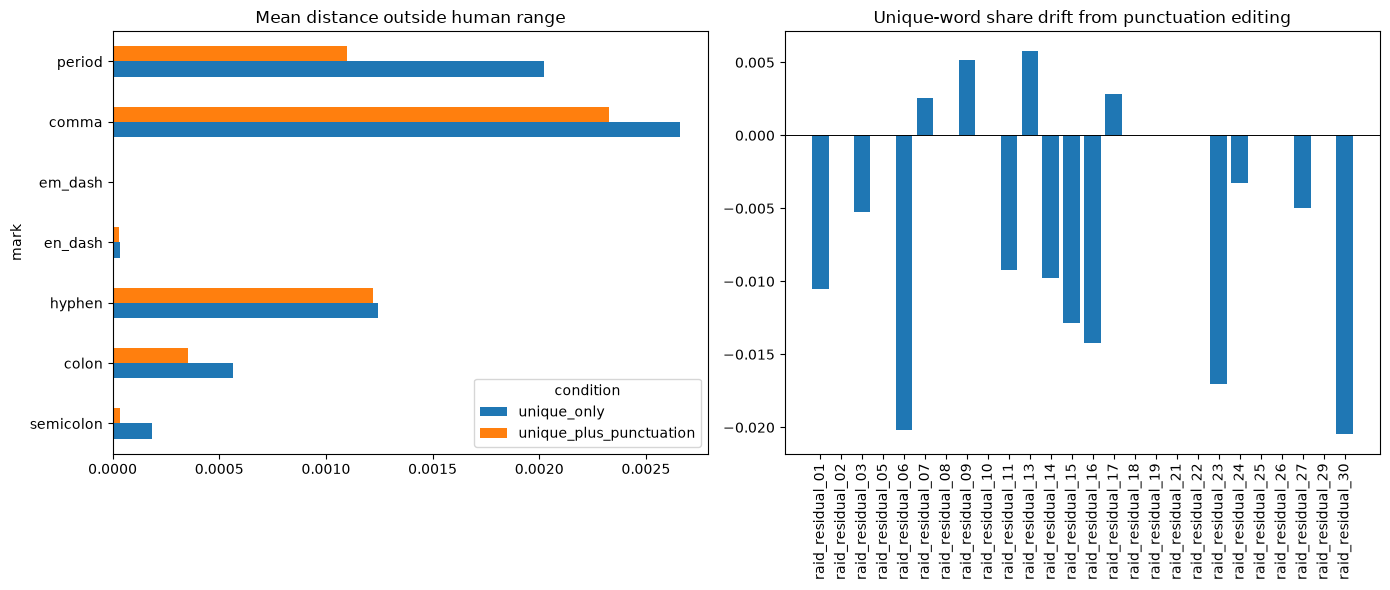


 raid_residual_01 
BEFORE:
 We introduce a new method for finding the best solution in a Markov Random Field (MRF) problem. This method uses a smooth, non-convex, and non-convex-convex optimization algorithm based on the smooth Riemannian optimization problem. We also demonstrate that the optimal solution can be achieved through another approach using the same algorithmic framework. Our findings suggest that the proposed methods are effective in solving complex MRF problems. 
AFTER:
 We introduce a new method for finding the best solution in a Markov Random Field (MRF) problem and this method uses a smooth, non-convex, and non-convex-convex optimization algorithm based on the smooth Riemannian optimization problem. We also demonstrate that the optimal solution can be achieved through another approach using the same algorithmic framework. Our findings suggest that the proposed methods are effective in solving complex MRF problems.

 raid_residual_02 
BEFORE:
 The Science of Discworld b

In [7]:
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
records=[];vectors=[];outcomes=[];audit=[];reviews=[]
for c,s in results:
    for condition,t in [('unique_only',c['text']),('unique_plus_punctuation',s['text'])]:
        vector=extract_fz118(normalize(t));vectors.append(vector)
        records.append(dict(case_id=c['case_id'],condition=condition))
        for m,r in c['bounds'].items():
            value=rates(t)[m]
            outcomes.append(dict(case_id=c['case_id'],condition=condition,mark=m,value=value,
                count=t.count(MARKS[m]),**r,in_band=r['low']<=value<=r['high'],band_distance=distance(value,r)))
    audit.extend([dict(case_id=c['case_id'],**e) for e in s['audit']])
    reviews.append(dict(case_id=c['case_id'],domain=c['domain'],before=c['text'],after=s['text'],
        unique_before=unique(c['text']),unique_after=unique(s['text']),
        unique_change=unique(s['text'])-unique(c['text']),n_edits=len(s['audit'])))
index=pd.MultiIndex.from_frame(pd.DataFrame(records))
frame=pd.DataFrame(vectors,index=index,columns=FEATURE_NAMES)
frame.to_csv(OUT/'all_feature_values.csv')
punct=pd.DataFrame(outcomes);punct.to_csv(OUT/'punctuation_outcomes.csv',index=False)
pd.DataFrame(audit).to_csv(OUT/'accepted_edits.csv',index=False)
review=pd.DataFrame(reviews);review.to_csv(OUT/'text_pairs.csv',index=False)
manual=OUT/'manual_review.csv'
if not manual.exists():review.assign(meaning_preserved='',grammar_acceptable='',notes='').to_csv(manual,index=False)
scores=pd.Series(detector.predict_proba(frame[model_features])[:,1],index=index).unstack('condition')
scores['change']=scores.unique_plus_punctuation-scores.unique_only
scores.to_csv(OUT/'detector_scores.csv');display(scores)
display(punct.groupby(['mark','condition']).agg(mean=('value','mean'),in_band=('in_band','mean'),distance=('band_distance','mean')))
display(review[['case_id','n_edits','unique_before','unique_after','unique_change']])
# Full feature drift is descriptive; primary outcomes are punctuation band distances.
delta=frame.xs('unique_plus_punctuation',level='condition')-frame.xs('unique_only',level='condition')
delta.to_csv(OUT/'feature_changes.csv')
fig,axes=plt.subplots(1,2,figsize=(14,6))
a=punct.pivot_table(index='mark',columns='condition',values='band_distance').reindex(list(MARKS))
a.plot.barh(ax=axes[0]);axes[0].set_title('Mean distance outside human range')
axes[1].bar(review.case_id,review.unique_change);axes[1].tick_params(axis='x',rotation=90)
axes[1].set_title('Unique-word share drift from punctuation editing');axes[1].axhline(0,color='black',lw=.7)
fig.tight_layout();fig.savefig(OUT/'punctuation_outcomes.png',dpi=180);plt.show()
for row in review.head(3).itertuples():
    print('\n',row.case_id,'\nBEFORE:\n',row.before,'\nAFTER:\n',row.after)

Lower score = more human-like to this frozen detector.
Change = after − before; negative values indicate improvement.


condition,unique_only,unique_plus_punctuation,change,reduction
case_id,,,,
raid_residual_01,0.410804,0.361790,-0.049015,0.049015
raid_residual_02,0.471135,0.473213,0.002079,-0.002079
raid_residual_03,0.615016,0.654417,0.039402,-0.039402
raid_residual_05,0.660272,0.660272,0.000000,-0.000000
raid_residual_06,0.433422,0.535672,0.102250,-0.102250
raid_residual_07,0.413644,0.355665,-0.057980,0.057980
raid_residual_08,0.522334,0.522334,0.000000,-0.000000
raid_residual_09,0.452777,0.459039,0.006262,-0.006262
raid_residual_10,0.550788,0.481240,-0.069548,0.069548


,mean,median
condition,,
unique_only,0.520691,0.532874
unique_plus_punctuation,0.521428,0.525077


Lower scores: 10/26 | Mean change: +0.000737 | Median change: +0.000000


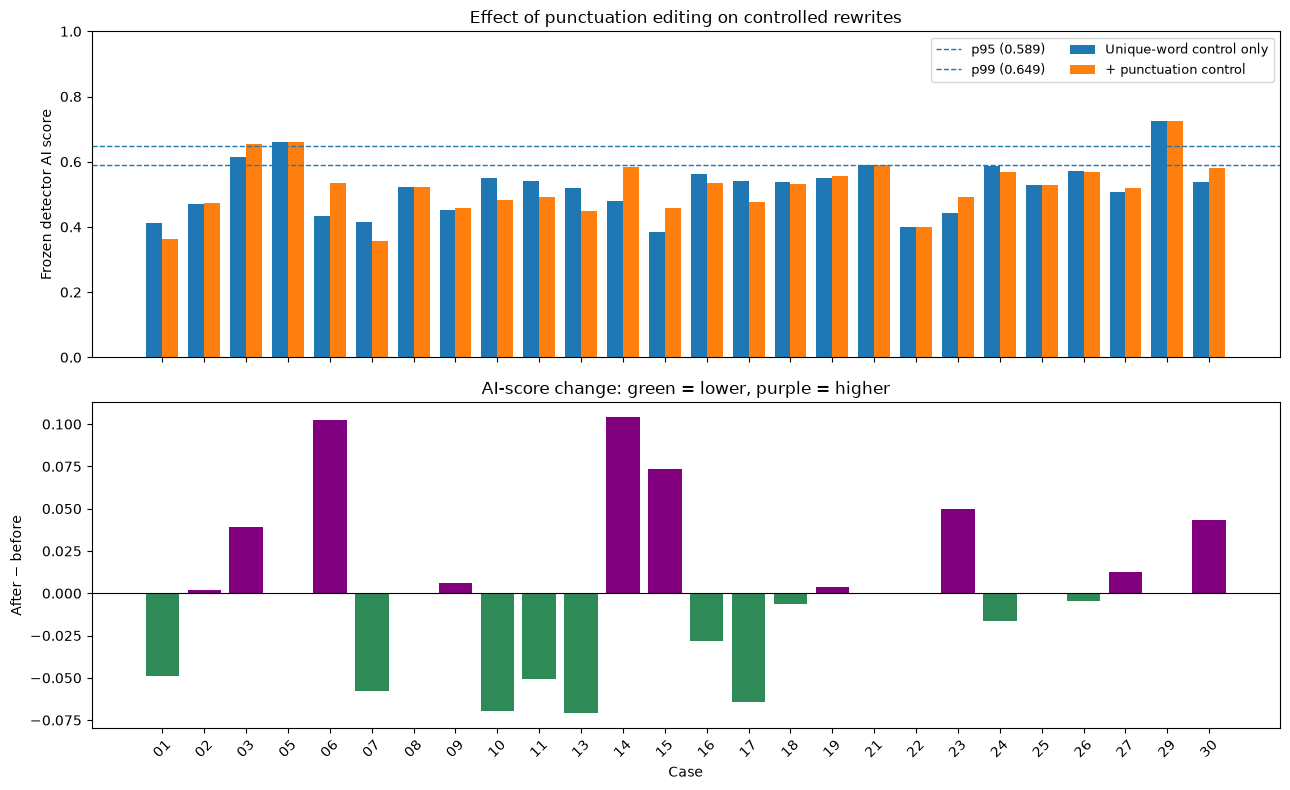

,mean_reduction,median_reduction,mean_absolute_change,fraction_lower_AI
feature,,,,
pos_1gram_overlap_bin_9,0.003093,0.000000,0.005560,0.461538
punct_relative_semicolon,-0.005008,0.000000,0.005277,0.307692
pos_3gram_overlap_bin_0,-0.000609,0.000000,0.004014,0.423077
punct_relative_colon,0.003069,0.000000,0.003990,0.384615
pos_2gram_overlap_bin_1,0.000595,0.000000,0.003865,0.461538
pos_3gram_overlap_bin_2,0.000261,0.000000,0.003684,0.384615
punct_relative_period,-0.001692,0.000000,0.003571,0.269231
punct_per_sentence_semicolon,-0.003074,-0.000153,0.003402,0.153846
word_1gram_overlap_bin_0,0.000398,0.000000,0.003307,0.423077


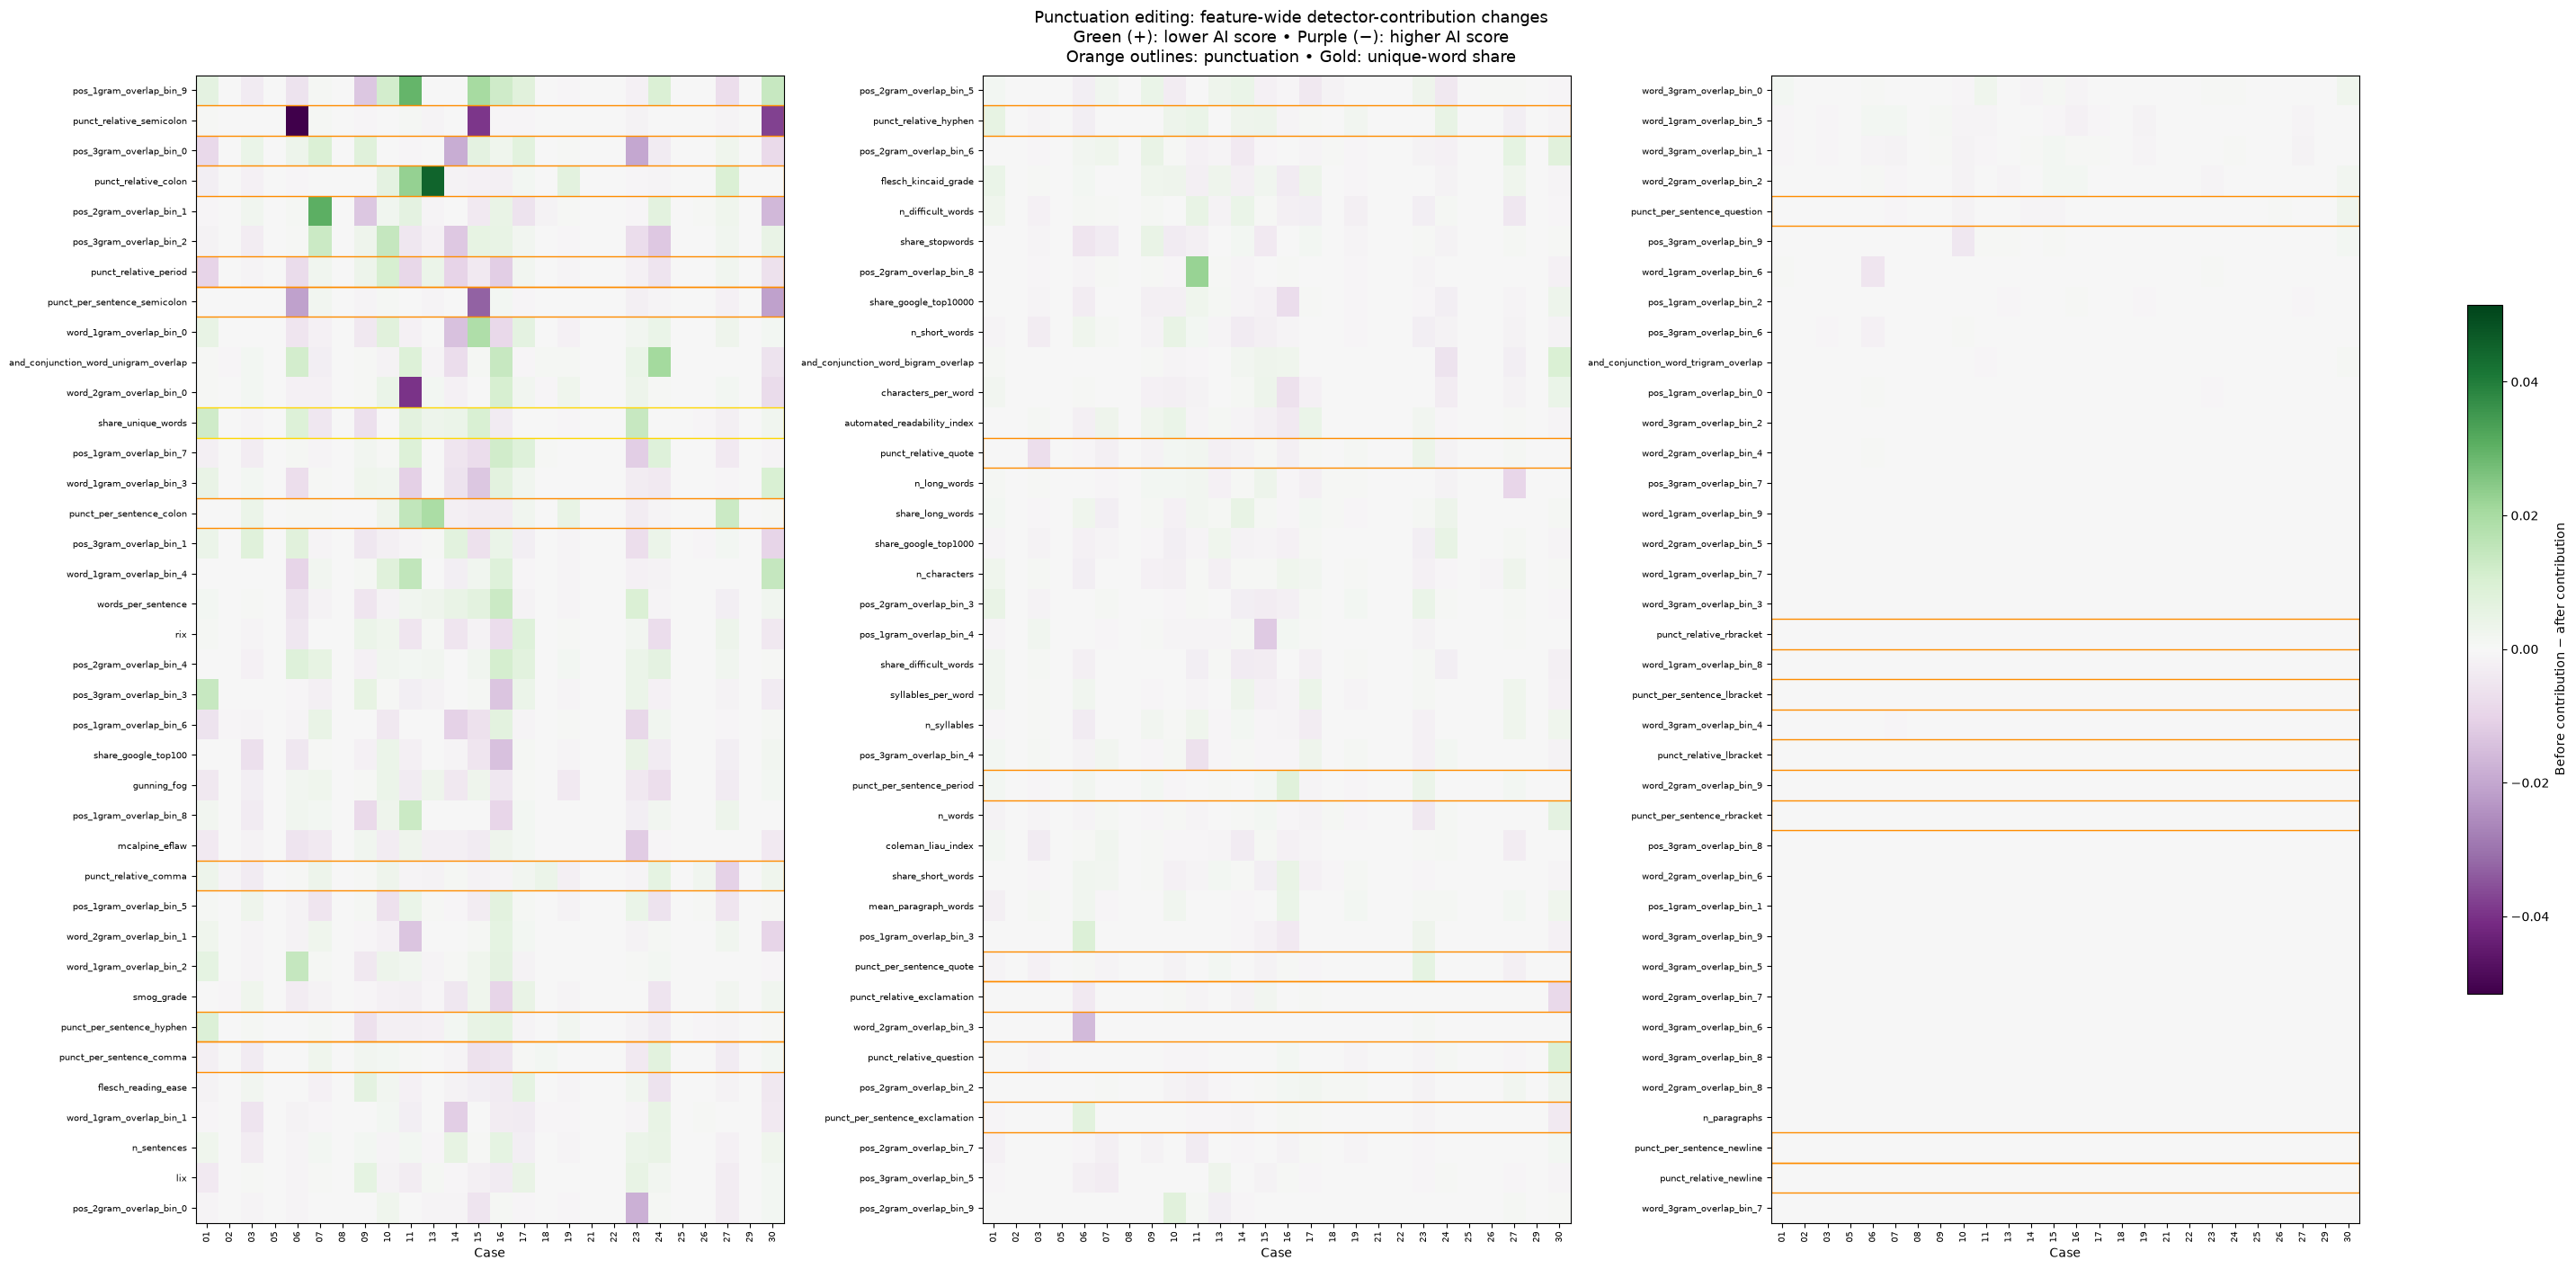

Verified: feature-contribution reductions sum to each AI-score reduction.
Saved score tables, contribution tables, ranking, and graphs to: ../results/causal/C02k_punctuation_stacks


In [8]:
# C02k: AI-score changes + exact tree-path contribution changes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

BEFORE = "unique_only"
AFTER = "unique_plus_punctuation"

X = frame.loc[:, model_features].copy()
assert list(detector.classes_) == [0, 1]
assert X.index.is_unique

probabilities = pd.Series(
    detector.predict_proba(X)[:, 1], index=X.index, name="AI_score"
)
comparison = probabilities.unstack("condition")[[BEFORE, AFTER]]
assert comparison.notna().all().all()
comparison["change"] = comparison[AFTER] - comparison[BEFORE]
comparison["reduction"] = -comparison["change"]
comparison.to_csv(OUT / "punctuation_AI_score_changes.csv")

print("Lower score = more human-like to this frozen detector.")
print("Change = after − before; negative values indicate improvement.")
display(comparison.round(6))
display(pd.DataFrame({
    "mean": comparison[[BEFORE, AFTER]].mean(),
    "median": comparison[[BEFORE, AFTER]].median(),
}))
print(
    f"Lower scores: {(comparison.change < -1e-10).sum()}/{len(comparison)}"
    f" | Mean change: {comparison.change.mean():+.6f}"
    f" | Median change: {comparison.change.median():+.6f}"
)

case_ids = comparison.index.tolist()
labels = [str(c).rsplit("_", 1)[-1] for c in case_ids]
positions = np.arange(len(case_ids))

fig, axes = plt.subplots(
    2, 1, figsize=(max(13, len(case_ids) * .48), 8), sharex=True
)
axes[0].bar(
    positions - .19, comparison[BEFORE], width=.38,
    label="Unique-word control only", color="tab:blue"
)
axes[0].bar(
    positions + .19, comparison[AFTER], width=.38,
    label="+ punctuation control", color="tab:orange"
)

op_path = PRIOR / "raid_operating_points_p95_p99.csv"
if op_path.exists():
    for op in pd.read_csv(op_path).itertuples():
        threshold = float(op.validation_human_threshold)
        name = f"p{round(op.human_specificity_target * 100)}"
        axes[0].axhline(
            threshold, linestyle="--", linewidth=1,
            label=f"{name} ({threshold:.3f})"
        )
        comparison[f"{name}_crossed_below"] = (
            (comparison[BEFORE] >= threshold)
            & (comparison[AFTER] < threshold)
        )

axes[0].set(
    ylabel="Frozen detector AI score", ylim=(0, 1),
    title="Effect of punctuation editing on controlled rewrites"
)
axes[0].legend(fontsize=9, ncol=2)

axes[1].bar(
    positions, comparison.change,
    color=np.where(comparison.change <= 0, "seagreen", "purple")
)
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set(
    ylabel="After − before", xlabel="Case",
    title="AI-score change: green = lower, purple = higher"
)
axes[1].set_xticks(positions, labels, rotation=45)
fig.tight_layout()
fig.savefig(OUT / "punctuation_AI_score_changes.png", dpi=180)
plt.show()
comparison.to_csv(OUT / "punctuation_AI_score_changes.csv")

# Exact additive tree-path decomposition of predict_proba.
# This is detector accounting, not SHAP or a causal attribution.
values = X.to_numpy(dtype=np.float32)
contributions = np.zeros(values.shape, dtype=np.float64)
bias = 0.0

for estimator in detector.estimators_:
    tree = estimator.tree_
    counts = tree.value[:, 0, :]
    node_probability = counts[:, 1] / counts.sum(axis=1)
    bias += node_probability[0]

    for row in range(len(values)):
        node = 0
        while tree.feature[node] >= 0:
            feature = tree.feature[node]
            child = (
                tree.children_left[node]
                if values[row, feature] <= tree.threshold[node]
                else tree.children_right[node]
            )
            contributions[row, feature] += (
                node_probability[child] - node_probability[node]
            )
            node = child

contributions /= len(detector.estimators_)
bias /= len(detector.estimators_)
np.testing.assert_allclose(
    bias + contributions.sum(axis=1),
    probabilities.to_numpy(), atol=1e-9, rtol=0
)

cf = pd.DataFrame(
    contributions, index=X.index, columns=model_features
)
# Positive movement means a reduction in the AI score.
movement = (
    cf.xs(BEFORE, level="condition").loc[case_ids]
    - cf.xs(AFTER, level="condition").loc[case_ids]
)
np.testing.assert_allclose(
    movement.sum(axis=1), comparison.reduction,
    atol=1e-9, rtol=0
)
cf.to_csv(OUT / "punctuation_detector_contributions.csv")
movement.to_csv(OUT / "punctuation_contribution_reductions.csv")

ranking = pd.DataFrame({
    "mean_reduction": movement.mean(),
    "median_reduction": movement.median(),
    "mean_absolute_change": movement.abs().mean(),
    "fraction_lower_AI": (movement > 1e-10).mean(),
}).sort_values("mean_absolute_change", ascending=False)
ranking.index.name = "feature"
ranking.to_csv(OUT / "punctuation_contribution_ranking.csv")
display(ranking.head(25).round(6))

# All detector features, split across three panels.
order = ranking.index.tolist()
limit = max(float(movement.abs().to_numpy().max()), 1e-8)
blocks = np.array_split(np.asarray(order), 3)
fig, axes = plt.subplots(
    1, 3, figsize=(max(27, len(case_ids) * 1.1), 14),
    layout="constrained"
)
annotate = len(case_ids) <= 12

for ax, block in zip(axes, blocks):
    data = movement.loc[:, block].T
    im = ax.imshow(
        data, cmap="PRGn", vmin=-limit, vmax=limit, aspect="auto"
    )
    ax.set_yticks(np.arange(len(block)), block, fontsize=7)
    ax.set_xticks(positions, labels, rotation=90, fontsize=7)
    ax.set_xlabel("Case")

    for row, feature in enumerate(block):
        if feature.startswith("punct_") or feature == "share_unique_words":
            color = "darkorange" if feature.startswith("punct_") else "gold"
            ax.add_patch(Rectangle(
                (-.5, row-.5), len(case_ids), 1,
                fill=False, edgecolor=color, linewidth=1
            ))
        if annotate:
            for col, value in enumerate(data.iloc[row]):
                ax.text(
                    col, row,
                    "·" if abs(value) < 1e-9 else f"{value:+.3f}",
                    ha="center", va="center", fontsize=5,
                    color="white" if abs(value) > .6 * limit else "black"
                )

fig.suptitle(
    "Punctuation editing: feature-wide detector-contribution changes\n"
    "Green (+): lower AI score • Purple (−): higher AI score\n"
    "Orange outlines: punctuation • Gold: unique-word share",
    fontsize=13
)
fig.colorbar(
    im, ax=list(axes), shrink=.6,
    label="Before contribution − after contribution"
)
fig.savefig(
    OUT / "punctuation_contribution_heatmap.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("Verified: feature-contribution reductions sum to each AI-score reduction.")
print("Saved score tables, contribution tables, ranking, and graphs to:", OUT)